# Task 6 — Netflix Business Insights Report

## Step 1: Exploratory Data Analysis (EDA)

### Objective
Perform an overall analysis of the cleaned Netflix dataset to understand its structure, data quality, content distribution, and key characteristics.

### Analysis Plan
- Inspect the dataset dimensions and columns.
- Check missing values and duplicate records.
- Analyze Movies and TV Shows.
- Review country, release year, rating, and genre distributions.
- Identify useful patterns for the final business report.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned Netflix dataset
df = pd.read_csv("../../data/processed/netflix_cleaned.csv")

# Display dataset dimensions
print("Rows and columns:", df.shape)

# Display column names
print("\nColumns:")
print(df.columns.tolist())

# Display first five records
df.head()

Rows and columns: (8790, 12)

Columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'duration_value', 'duration_unit']


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


### Check Data Quality

Before combining the previous analyses, inspect missing values and duplicate records to understand the quality of the cleaned dataset.

In [2]:
# Check missing values in each column
print("Missing values by column:")
print(df.isna().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values by column:
show_id           0
type              0
title             0
director          0
country           0
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
duration_value    0
duration_unit     0
dtype: int64

Duplicate rows: 0


### Overall Content Distribution

Analyze the number of Movies and TV Shows in the dataset to understand its overall composition.

In [3]:
# Count Movies and TV Shows
content_counts = df["type"].value_counts()

print("Content type distribution:")
print(content_counts)

# Calculate percentages
content_percentages = (
    df["type"].value_counts(normalize=True) * 100
).round(2)

print("\nContent type percentages:")
print(content_percentages)

Content type distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Content type percentages:
type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64


## Step 2: Identify Key Content Trends and Patterns

Combine findings from country, release year, rating, genre, and content type analyses to identify the most important patterns in the Netflix dataset.

In [6]:
# Summarize key content patterns
print("Total records:", len(df))

print("\nTop 5 countries:")
print(df["country"].value_counts().head(5))

print("\nTop 5 release years:")
print(df["release_year"].value_counts().head(5))

print("\nTop 5 ratings:")
print(df["rating"].value_counts().head(5))

print("\nTop 5 genres:")
print(df["listed_in"].str.split(",").explode().str.strip().value_counts().head(5))

print("\nContent type percentages:")
print(content_percentages)

Total records: 8790

Top 5 countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Name: count, dtype: int64

Top 5 release years:
release_year
2018    1146
2019    1030
2017    1030
2020     953
2016     901
Name: count, dtype: int64

Top 5 ratings:
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
Name: count, dtype: int64

Top 5 genres:
listed_in
International Movies      2752
Dramas                    2426
Comedies                  1674
International TV Shows    1349
Documentaries              869
Name: count, dtype: int64

Content type percentages:
type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64


## Step 3: Develop Visual Dashboards

Create a multi-chart dashboard that summarizes Netflix content type distribution, release-year trends, ratings, and the most common genres.

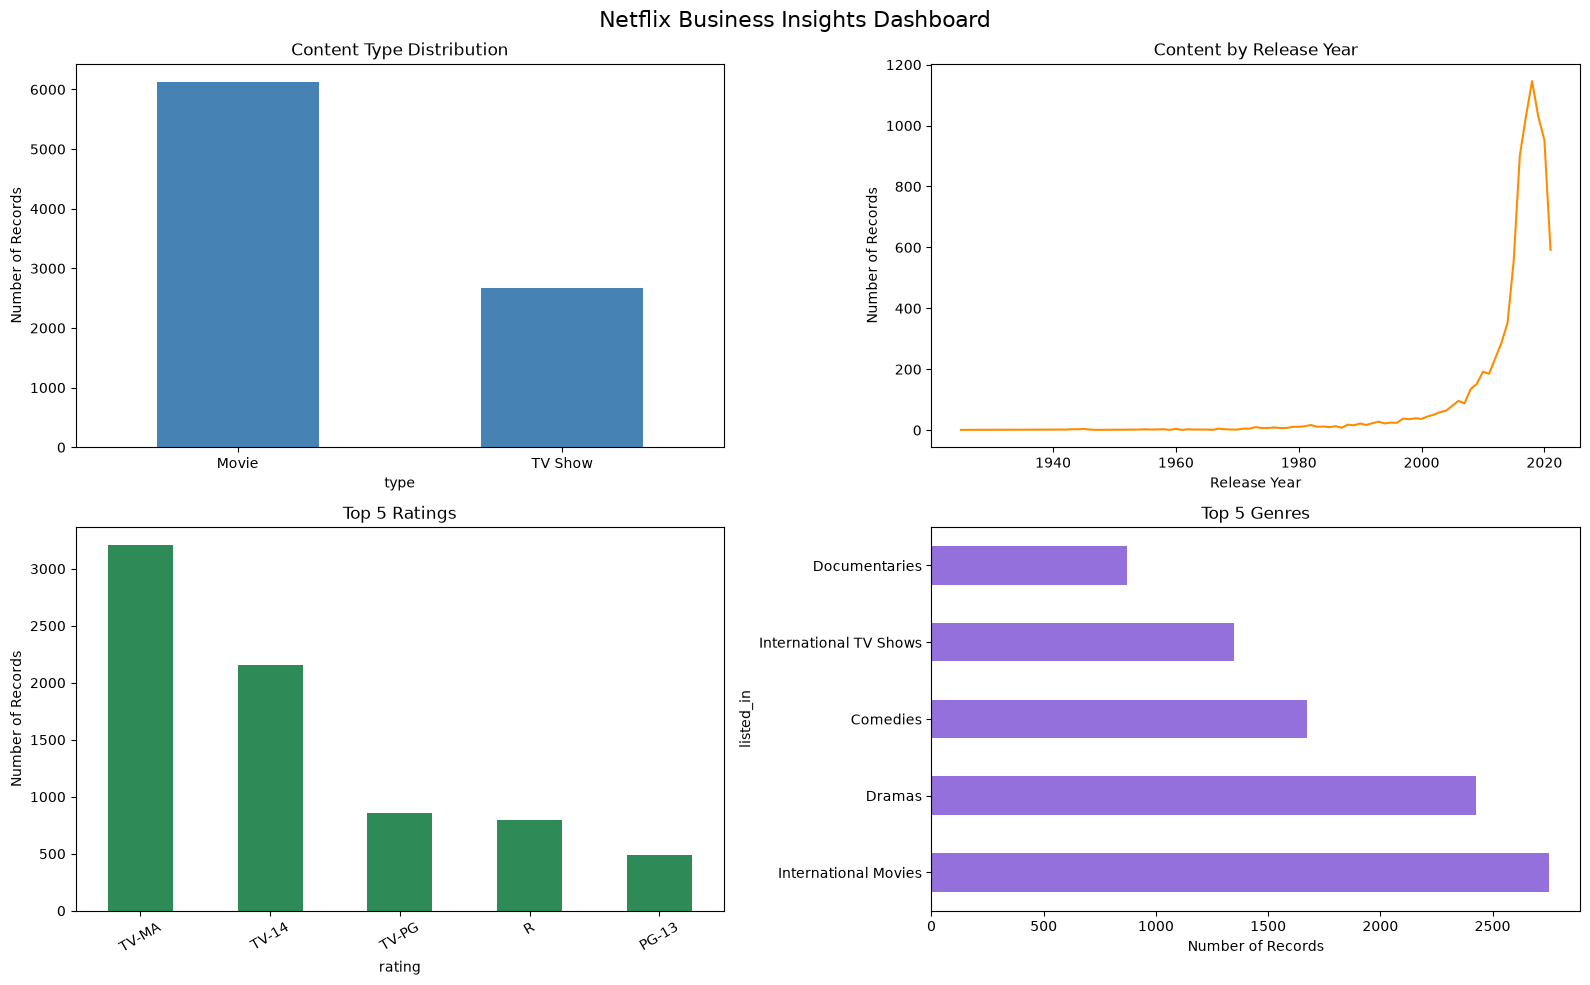

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Content type distribution
df["type"].value_counts().plot(
    kind="bar", ax=axes[0, 0], color="steelblue"
)
axes[0, 0].set_title("Content Type Distribution")
axes[0, 0].set_ylabel("Number of Records")
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Release-year trend
df["release_year"].value_counts().sort_index().plot(
    kind="line", ax=axes[0, 1], color="darkorange"
)
axes[0, 1].set_title("Content by Release Year")
axes[0, 1].set_xlabel("Release Year")
axes[0, 1].set_ylabel("Number of Records")

# 3. Top ratings
df["rating"].value_counts().head(5).plot(
    kind="bar", ax=axes[1, 0], color="seagreen"
)
axes[1, 0].set_title("Top 5 Ratings")
axes[1, 0].set_ylabel("Number of Records")
axes[1, 0].tick_params(axis="x", rotation=30)

# 4. Top genres
df["listed_in"].dropna().str.split(",").explode().str.strip().value_counts().head(5).plot(
    kind="barh", ax=axes[1, 1], color="mediumpurple"
)
axes[1, 1].set_title("Top 5 Genres")
axes[1, 1].set_xlabel("Number of Records")

plt.suptitle("Netflix Business Insights Dashboard", fontsize=16)
plt.tight_layout()
plt.savefig("netflix_business_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 4: Generate Actionable Business Insights

### Key Findings

1. **Content mix:** Movies account for 69.69% of records, while TV Shows account for 30.31%.
2. **Country distribution:** The United States has the highest country count, followed by India and the United Kingdom.
3. **Release-year trend:** The number of records peaks in 2018 and declines in the dataset for 2019–2021.
4. **Rating distribution:** TV-MA is the most common rating, followed by TV-14.
5. **Genre distribution:** International Movies, Dramas, and Comedies are the most frequently listed categories.

### Recommendations

- Review the balance between Movies and TV Shows when planning future catalog analysis.
- Examine regional content distribution to understand the geographic coverage of the catalog.
- Investigate release-year declines before drawing conclusions about production or acquisition strategy.
- Compare rating and genre distributions when planning content categories for different audiences.

### Limitations

These recommendations are based on catalog records, not viewership, revenue, or customer preferences. Additional audience and performance data would be required to make investment or content acquisition decisions.

# Final Analytical Report — Netflix Business Insights

## 1. Project Overview
This project analyzes the Netflix catalog using Python, Pandas, and Matplotlib to identify content distribution patterns, release-year trends, rating categories, and genres.

## 2. Dataset Summary
- Total records: 8,790
- Total columns: 12
- Missing values in the cleaned dataset: 0
- Exact duplicate rows: 0

## 3. Key Findings
- Movies: 6,126 records (69.69%)
- TV Shows: 2,664 records (30.31%)
- Leading country in the current cleaned data: United States (3,240 records)
- Most common rating: TV-MA (3,205 records)
- Most common genre/category: International Movies (2,752 records)
- Highest release-year count: 2018 (1,146 records)

## 4. Business Insights
The catalog contains more Movie records than TV Show records. TV-MA and TV-14 are the most frequent ratings, while International Movies, Dramas, and Comedies are the most frequently listed categories.

The release-year distribution peaks in 2018 and declines in the dataset for 2019–2021. This pattern should be investigated further before drawing conclusions about Netflix's production or acquisition decisions.

## 5. Recommendations
- Review the balance of Movies and TV Shows when analyzing catalog composition.
- Explore geographic representation and genre distribution in more detail.
- Investigate release-year patterns using additional data before making strategic decisions.
- Combine catalog data with viewership, revenue, and audience research before making investment recommendations.

## 6. Limitations
This analysis measures catalog records and category frequencies, not viewership, revenue, or audience preferences. Genre counts may overlap because titles can have multiple genres. Country counts may also be affected by missing or transformed country information.

## 7. Tools Used
- Python
- Pandas
- Matplotlib
- Plotly
- Jupyter Notebook

## 8. Conclusion
The analysis summarizes Netflix's catalog composition and identifies notable patterns across content type, country, release year, ratings, and genres. These findings provide a starting point for further business analysis.

## Status
Analysis and reporting drafted; final file verification pending.